# Lesson 3: Levels, peak, RMS and dBFS
*DSP Lab, Day 3 · Saturday 14 November 2026*

Audacity has two effects that both make a clip louder: **Amplify** and **Normalize**. This lesson works out what each one does to the samples, and why "loud" is not the same as "high peak".

**You will learn**
- what dBFS means, and how to convert between amplitude and decibels
- the difference between peak level and RMS level, and what the crest factor tells you
- what Amplify does to the samples, and what clipping looks and sounds like
- what Normalize does, including removing a DC offset
- why two clips with the same peak can sound very different in loudness

**References**
- J. O. Smith, *Mathematics of the DFT*, appendix on decibels: https://ccrma.stanford.edu/~jos/mdft/Decibels.html
- S. W. Smith, *The Scientist and Engineer's Guide to DSP*, ch. 2, Statistics, Probability and Noise (mean, standard deviation and RMS): https://www.dspguide.com/ch2.htm
- Audacity Manual (manual.audacityteam.org): Amplify, Normalize, Loudness Normalization

> Turn your volume down before playing the clips in section 3. Clipping is meant to sound harsh.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
from IPython.display import Audio, display

try:
    y, sr = librosa.load(librosa.ex('trumpet'))
    source = "librosa's trumpet example"
except Exception:
    # Fallback when the example cannot be downloaded: a decaying 440 Hz tone
    sr = 22050
    t = np.arange(3 * sr) / sr
    y = (0.3 * np.sin(2 * np.pi * 440 * t) * np.exp(-t)).astype(np.float32)
    source = "a synthetic 440 Hz tone (the trumpet example could not be loaded)"

print(f"{source}: {len(y)} samples at {sr} Hz = {len(y) / sr:.2f} s")
display(Audio(y, rate=sr, normalize=False))

librosa's trumpet example: 117601 samples at 22050 Hz = 5.33 s


## 1. Decibels relative to full scale (dBFS)

Digital audio samples live between −1 and +1. The largest possible sample, 1.0, is called **full scale**, and levels are measured in decibels below it:

$$\text{level (dBFS)} = 20 \log_{10} |a|$$

- 1.0 is 0 dBFS, the loudest a sample can be.
- 0.5 is about −6 dBFS. Halving the amplitude always takes about 6 dB off.
- 0.1 is −20 dBFS.

Why 20 and not 10? Decibels compare **power**, and power goes with amplitude squared: 10·log10(a²) = 20·log10(a).

In [2]:
def to_db(a):
    """Amplitude (or array of amplitudes) to dBFS. Tiny values are floored to avoid log(0)."""
    return 20 * np.log10(np.maximum(np.abs(a), 1e-12))

def from_db(db):
    """dB to an amplitude factor."""
    return 10 ** (db / 20)

for a in [1.0, 0.5, 0.25, 0.1, 0.01]:
    print(f"amplitude {a:>5}  ->  {to_db(a):7.2f} dBFS")

amplitude   1.0  ->     0.00 dBFS
amplitude   0.5  ->    -6.02 dBFS
amplitude  0.25  ->   -12.04 dBFS
amplitude   0.1  ->   -20.00 dBFS
amplitude  0.01  ->   -40.00 dBFS


## 2. Peak, RMS and crest factor

- **Peak** is the largest sample, ignoring sign. It tells you how close the clip is to clipping.
- **RMS** (root mean square) is the square root of the average of the squared samples. It measures average power, and follows how loud something sounds much better than peak does.
- **Crest factor** is peak minus RMS, in dB. Spiky sounds (drums, the attack of a trumpet note) have a high crest factor. A sine wave's is always 3.01 dB, and a square wave's is 0 dB, because every sample of a square wave is at its peak.

In [3]:
def levels(x):
    peak = np.max(np.abs(x))
    rms = np.sqrt(np.mean(x.astype(np.float64) ** 2))
    return to_db(peak), to_db(rms), to_db(peak) - to_db(rms)

t = np.arange(sr) / sr
sine = 0.5 * np.sin(2 * np.pi * 440 * t)
square = 0.5 * np.sign(np.sin(2 * np.pi * 440 * t))

print(f"{'signal':8s} {'peak':>10s} {'RMS':>10s} {'crest':>8s}")
for name, x in [("clip", y), ("sine", sine), ("square", square)]:
    p, r, c = levels(x)
    print(f"{name:8s} {p:7.1f} dBFS {r:7.1f} dBFS {c:6.1f} dB")

signal         peak        RMS    crest
clip        -3.3 dBFS   -22.3 dBFS   19.0 dB
sine        -6.0 dBFS    -9.0 dBFS    3.0 dB
square      -6.0 dBFS    -6.0 dBFS    0.0 dB


### The waveform in dB

Audacity can draw a track as **Waveform (dB)** from the track's dropdown menu. Quiet detail that is invisible on the linear scale becomes visible, because every 6 dB step gets the same height.

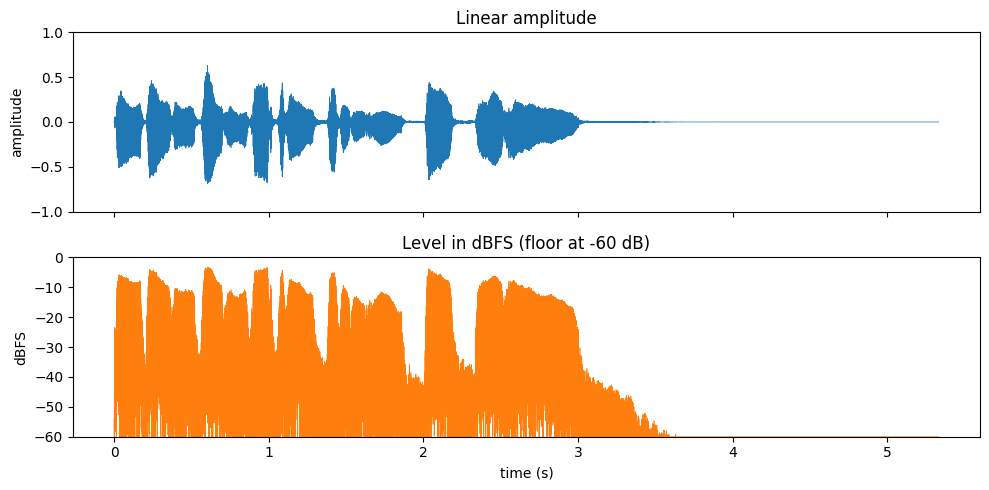

In [4]:
time = np.arange(len(y)) / sr
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
a1.plot(time, y, lw=0.5)
a1.set(title='Linear amplitude', ylabel='amplitude', ylim=(-1, 1))
a2.plot(time, np.maximum(to_db(y), -60), lw=0.5, color='tab:orange')
a2.set(title='Level in dBFS (floor at -60 dB)', ylabel='dBFS', xlabel='time (s)', ylim=(-60, 0))
plt.tight_layout()
plt.show()

## 3. Amplify: multiply every sample by the same gain

Amplify by *g* dB multiplies every sample by 10^(g/20). Nothing else changes: the shape of the waveform, and so its crest factor, stays the same.

Audacity's Amplify dialog opens with the gain that would bring the peak exactly to 0 dBFS, and refuses anything more unless you tick **Allow clipping**. Past full scale, a sample cannot be stored, so it is cut off at ±1. That flat top is **clipping**. It adds harmonics that were never in the sound, which is why it sounds harsh.

In [5]:
def amplify(x, gain_db):
    return x * from_db(gain_db)

peak_db = to_db(np.max(np.abs(y)))
max_gain = -peak_db
print(f"Current peak: {peak_db:.2f} dBFS, so the most gain without clipping is {max_gain:.2f} dB")

clean = amplify(y, max_gain)              # peak lands exactly on 0 dBFS
too_loud = amplify(y, max_gain + 6)       # 6 dB more than fits
clipped = np.clip(too_loud, -1.0, 1.0)
n = int(np.sum(np.abs(too_loud) > 1.0))
print(f"With {max_gain + 6:.2f} dB of gain, {n} samples ({100 * n / len(y):.2f}%) passed full scale and were clipped")

Current peak: -3.29 dBFS, so the most gain without clipping is 3.29 dB
With 9.29 dB of gain, 1423 samples (1.21%) passed full scale and were clipped


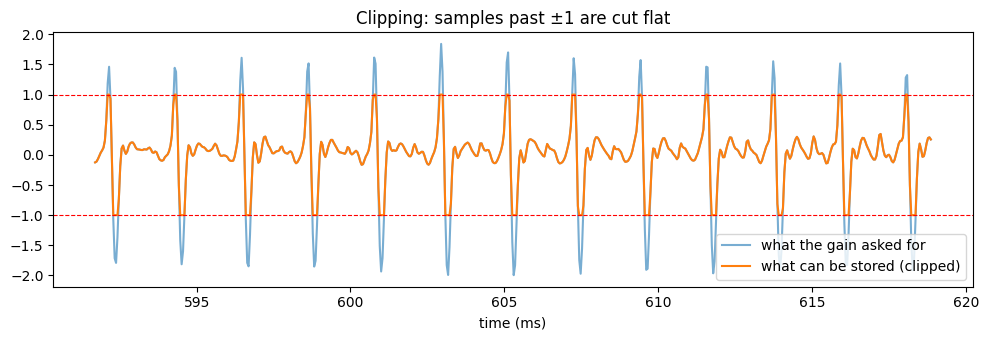

Amplified to 0 dBFS (clean):


6 dB too much (clipped):


In [6]:
i = int(np.argmax(np.abs(too_loud)))
lo, hi = max(i - 300, 0), min(i + 300, len(y))
zoom = np.arange(lo, hi) / sr * 1000
plt.figure(figsize=(10, 3.5))
plt.plot(zoom, too_loud[lo:hi], label='what the gain asked for', alpha=0.6)
plt.plot(zoom, clipped[lo:hi], label='what can be stored (clipped)', lw=1.5)
plt.axhline(1, color='red', ls='--', lw=0.8)
plt.axhline(-1, color='red', ls='--', lw=0.8)
plt.title('Clipping: samples past ±1 are cut flat')
plt.xlabel('time (ms)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

excerpt = slice(0, int(2.5 * sr))
print("Amplified to 0 dBFS (clean):")
display(Audio(clean[excerpt], rate=sr, normalize=False))
print("6 dB too much (clipped):")
display(Audio(clipped[excerpt], rate=sr, normalize=False))

## 4. Normalize: aim the peak at a target

Normalize is Amplify with the gain worked out for you, so that the peak lands on a target level. Audacity's default target is −1.0 dB, which leaves a little room for later processing. It also has two options Amplify doesn't:

- **Remove DC offset.** A DC offset means the whole waveform is shifted up or down, so it is no longer centred on zero. Faulty recording hardware can cause it. It wastes headroom, because one side reaches full scale before the other, and it causes clicks where clips are edited together. Removing it means subtracting the mean.
- **Normalize stereo channels independently**, so each channel gets its own gain (not needed for this mono clip).

offset, DC kept      mean +0.214   max +0.891   min -0.520
offset, DC removed   mean +0.000   max +0.822   min -0.891


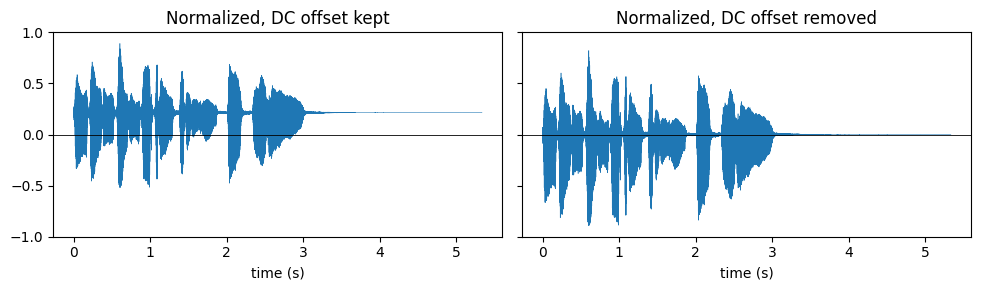

In [7]:
def normalize(x, target_dbfs=-1.0, remove_dc=True):
    x = x.astype(np.float64)
    if remove_dc:
        x = x - np.mean(x)
    return x * from_db(target_dbfs) / np.max(np.abs(x))

with_offset = y + 0.2   # simulate a DC offset of 0.2
plain = normalize(with_offset, remove_dc=False)
fixed = normalize(with_offset, remove_dc=True)

for name, x in [("offset, DC kept", plain), ("offset, DC removed", fixed)]:
    print(f"{name:20s} mean {np.mean(x):+.3f}   max {np.max(x):+.3f}   min {np.min(x):+.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, x, title in [(axes[0], plain, 'Normalized, DC offset kept'), (axes[1], fixed, 'Normalized, DC offset removed')]:
    ax.plot(time, x, lw=0.4)
    ax.axhline(0, color='k', lw=0.6)
    ax.set(title=title, xlabel='time (s)', ylim=(-1, 1))
plt.tight_layout()
plt.show()

With the offset kept, the positive side reaches −1 dBFS but the negative side stops well short, so the clip is quieter than it could be. With the offset removed, both sides use the full range.

## 5. Same peak, different loudness

Normalize the clip, a sine and a square wave to the same −1 dBFS peak and listen. They do not sound equally loud. RMS follows what you hear much more closely than peak does.

This is why Audacity also has **Loudness Normalization**, which targets a level in LUFS (loudness units relative to full scale). LUFS is an RMS-like measure, weighted for how the ear hears different frequencies. Streaming services and broadcasters normalise in LUFS, not by peak.

In [8]:
print(f"{'signal':8s} {'peak':>10s} {'RMS':>10s}")
for name, x in [("clip", y), ("sine", sine), ("square", square)]:
    xn = normalize(x, -1.0)
    p, r, _ = levels(xn)
    print(f"{name:8s} {p:7.1f} dBFS {r:7.1f} dBFS")
    display(Audio(xn[: 2 * sr], rate=sr, normalize=False))

signal         peak        RMS
clip        -1.0 dBFS   -20.0 dBFS


sine        -1.0 dBFS    -4.0 dBFS


square      -1.0 dBFS    -1.0 dBFS


## Try it in Audacity

Audacity is a free audio editor (audacityteam.org). These steps assume you have not used it before. Menu names move around between versions; Audacity 3.2 and later group effects into submenus.

1. **Make a test sound.** Open Audacity and choose **Generate › Tone…**. Set *Waveform* to Sine, *Frequency* to 440, *Amplitude* to 0.5 and *Duration* to 5 seconds, then press **Generate**. A blue band appears in a new track. That band is the waveform, drawn from −1 at the bottom to +1 at the top.
2. **Select it.** Click once inside the track, then press **Ctrl+A** to select everything. Selected audio turns a lighter colour.
3. **Amplify.** Choose **Effect › Volume and Compression › Amplify…** (in older versions, just **Effect › Amplify…**). The dialog already offers the gain that would bring the peak to 0 dB. For an amplitude of 0.5 it should say about 6.02 dB, the same number section 3 calculated. Press **Cancel**.
4. **Normalize.** Choose **Effect › Volume and Compression › Normalize…**, tick *Remove DC offset*, set the peak to −1.0 dB and press **Apply**. The band grows to almost the full height.
5. **See it in decibels.** Right-click the vertical ruler on the left of the track, or open the track's menu by clicking its name, and pick the logarithmic (dB) scale. Quiet parts become easier to see, like the dB plot in section 2.
6. **Compare with loudness.** Press **Ctrl+Z** to undo, then try **Effect › Volume and Compression › Loudness Normalization…** set to −23 LUFS. Play both versions with the space bar and listen for the difference.

## How AI uses this

Speech and audio models are trained on recordings made with very different microphones and volumes. Before training, and before a model listens to new audio, clips are usually brought to a similar level: peak normalised, RMS normalised or loudness normalised. Otherwise the model can end up learning "this was a quiet microphone" instead of "this was the word *yes*". Clipped recordings are a problem too: the flat tops add harmonics that were never in the voice.

## Exercises

1. Show on paper that a sine's crest factor is 3.01 dB: peak *A*, RMS *A*/√2.
2. Amplify the clip by `max_gain + g` for g = 1, 3, 6 and 12 dB, and plot the percentage of clipped samples against g.
3. Add two −6 dBFS sines at 440 Hz and 441 Hz. What is the peak of the sum, and how often does it happen? (Hint: listen. The pattern is called beating.)

## Summary

- dBFS = 20·log10(amplitude). 0 dBFS is the ceiling, and halving the amplitude takes 6 dB off.
- Peak says how close you are to clipping; RMS says how loud it is; crest factor is the gap between them.
- Amplify multiplies by a gain. Past 0 dBFS, samples are clipped flat and the sound turns harsh.
- Normalize picks the gain for you, can remove a DC offset first, and aims the peak at a target such as −1 dBFS.
- Equal peaks do not mean equal loudness. For that, use RMS or LUFS.